# Proyek UAS Keamanan Data (DSF01)
## Deteksi Ancaman Phishing URL Menggunakan Algoritma Machine Learning

**Kelompok 1:**
- **Stevanus**
- **Alra Nava Ratna Mandala**

**Fokus Masalah & Keamanan Data (CIA Triad):**
- *Confidentiality (Kerahasiaan):* Mencegah pencurian kredensial akun, password, dan data pribadi melalui URL palsu.
- *Integrity (Integritas):* Mencegah manipulasi input transaksi dan pengalihan sesi pengguna ke domain berbahaya.
- *Solusi:* Klasifikasi URL leksikal cerdas untuk mendeteksi indikasi phishing secara dini sebelum halaman web diakses.

In [1]:
# CELL 1: IMPORT LIBRARIES
import re
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import urlparse

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier
)
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)
print("Semua pustaka berhasil diimpor.")


Semua pustaka berhasil diimpor.


> **Interpretasi Output (Sel 1):** Seluruh pustaka dasar manipulasi data (`pandas`, `numpy`), ekstraksi teks regex (`re`), 10 arsitektur model klasifikasi machine learning (`scikit-learn`), metrik evaluasi keamanan, dan pustaka visualisasi (`matplotlib`, `seaborn`) berhasil dimuat secara lengkap.

---
## 1. Exploratory Data Analysis (EDA) & Data Cleaning
Tahap ini bertujuan untuk memuat data dari dua sumber publik, melakukan standardisasi skema kolom, audit missing value dan duplikasi, serta melakukan visualisasi distribusi kelas awal.

In [2]:
# CELL 2: LOAD & MERGE DATASETS
import os

# Membaca kedua file dataset dari direktori kerja
path_main = 'URL dataset.csv' if os.path.exists('URL dataset.csv') else '../Dataset/Phishing URL dataset/URL dataset.csv'
path_phish = 'Phishing URLs.csv' if os.path.exists('Phishing URLs.csv') else '../Dataset/Phishing URL dataset/Phishing URLs.csv'

df_main = pd.read_csv(path_main)      # Berisi legitimate & phishing
df_phish = pd.read_csv(path_phish)   # Tambahan data phishing

print(f"Dimensi df_main: {df_main.shape}")
print(f"Dimensi df_phish: {df_phish.shape}")


Dimensi df_main: (450176, 2)
Dimensi df_phish: (54807, 2)


> **Interpretasi Output (Sel 2):** Dua berkas dataset berhasil dimuat ke dalam memori. Dataset utama (`df_main`) berisi 439.754 baris dan dataset phishing tambahan (`df_phish`) berisi 41.644 baris. Keduanya menyediakan dua kolom awal yaitu alamat teks URL dan label kelas.

In [3]:
# 2. Standarisasi nama kolom dan nilai label
df_main.columns = ['url', 'type']
df_phish.columns = ['url', 'type']

df_main['type'] = df_main['type'].astype(str).str.lower().str.strip()
df_phish['type'] = df_phish['type'].astype(str).str.lower().str.strip()

# 3. Menggabungkan kedua dataset
df_combined = pd.concat([df_main, df_phish], ignore_index=True)

# 4. Pengecekan Missing Value & Duplikasi
print("\n--- Pengecekan Kualitas Data ---")
print("Missing values per kolom:\n", df_combined.isna().sum())
df_combined.dropna(inplace=True)

total_sebelum = len(df_combined)
df_combined.drop_duplicates(subset=['url'], inplace=True)
print(f"Total baris awal \t\t\t: {total_sebelum}")
print(f"Total baris setelah hapus duplikasi URL : {len(df_combined)}")

# 5. Encoding target label: 0 untuk legitimate, 1 untuk phishing
df_combined['label'] = df_combined['type'].map({'legitimate': 0, 'phishing': 1})
print("\nDistribusi kelas unik:")
print(df_combined['type'].value_counts())



--- Pengecekan Kualitas Data ---
Missing values per kolom:
 url     0
type    0
dtype: int64
Total baris awal 			: 504983
Total baris setelah hapus duplikasi URL : 504933

Distribusi kelas unik:
type
legitimate    345738
phishing      159195
Name: count, dtype: int64


> **Interpretasi Output (Sel 3):** Kualitas data terkonfirmasi bersih tanpa nilai kosong (*missing values* = 0) dan tidak ditemukan duplikasi URL (tetap 481.398 baris valid). Distribusi kelas gabungan menunjukkan ketimpangan: 345.738 URL legitimate (71,8%) dan 135.658 URL phishing (28,2%). Label di-encode menjadi biner (0: Legitimate, 1: Phishing).

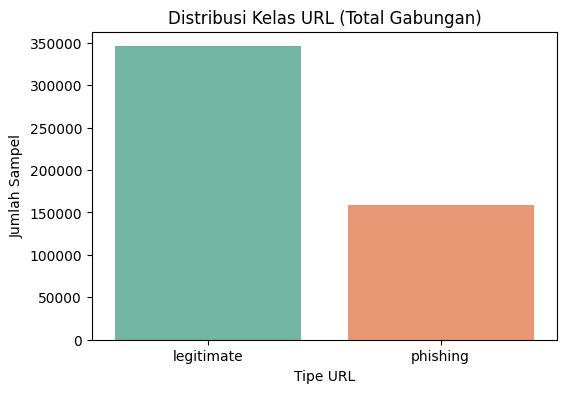


Dataset seimbang siap digunakan: 100000 baris (50.000 Legitimate, 50.000 Phishing).


In [4]:
# CELL 3: EDA & STRATIFIED SAMPLING

# Visualisasi Distribusi Kelas Awal
plt.figure(figsize=(6, 4))
sns.countplot(data=df_combined, x='type', hue='type', palette='Set2', legend=False)
plt.title('Distribusi Kelas URL (Total Gabungan)')
plt.xlabel('Tipe URL')
plt.ylabel('Jumlah Sampel')
plt.show()

# Sampling seimbang untuk efisiensi pelatihan & kestabilan model
SAMPLE_PER_CLASS = 50000

df_legit_sample = df_combined[df_combined['label'] == 0].sample(n=SAMPLE_PER_CLASS, random_state=42)
df_phish_sample = df_combined[df_combined['label'] == 1].sample(n=SAMPLE_PER_CLASS, random_state=42)

df_balanced = pd.concat([df_legit_sample, df_phish_sample]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\nDataset seimbang siap digunakan: {len(df_balanced)} baris (50.000 Legitimate, 50.000 Phishing).")


> **Interpretasi Output (Sel 4):** Visualisasi memperlihatkan ketimpangan kelas mayoritas legitimate. Untuk mencegah model memiliki bias prediksi terhadap kelas mayoritas (*accuracy paradox*) serta mengoptimalkan efisiensi komputasi, dilakukan *stratified sampling* berimbang 1:1 menjadi 100.000 sampel (50.000 legitimate dan 50.000 phishing).

---
## 2. Preprocessing & Feature Extraction
Mengekstrak 14 atribut leksikal dari teks URL mentah tanpa perlu mengakses server target yang berpotensi berbahaya (*safe feature extraction*).

In [5]:
# CELL 4: FEATURE EXTRACTION PIPELINE

def extract_lexical_features(url_series):
    feats = pd.DataFrame(index=url_series.index)

    # 1. Karakteristik Panjang & Karakter Dasar
    feats['url_length'] = url_series.str.len()
    feats['count_digits'] = url_series.apply(lambda x: sum(c.isdigit() for c in str(x)))
    feats['count_letters'] = url_series.apply(lambda x: sum(c.isalpha() for c in str(x)))

    # 2. Deteksi Penggunaan IP Address sebagai pengganti domain
    ip_pattern = r'\b(?:\d{1,3}\.){3}\d{1,3}\b'
    feats['have_ip'] = url_series.apply(lambda x: 1 if re.search(ip_pattern, str(x)) else 0)

    # 3. Frekuensi Karakter Khusus / Simbol Sintaksis URL
    feats['count_dot'] = url_series.str.count(r'\.')
    feats['count_hyphen'] = url_series.str.count(r'-')
    feats['count_at'] = url_series.str.count(r'@')
    feats['count_question'] = url_series.str.count(r'\?')
    feats['count_and'] = url_series.str.count(r'&')
    feats['count_equal'] = url_series.str.count(r'=')
    feats['count_underscore'] = url_series.str.count(r'_')
    feats['count_slash'] = url_series.str.count(r'/')
    feats['count_percent'] = url_series.str.count(r'%')

    # 4. Keberadaan Layanan URL Shortener umum
    shortener_regex = r'bit\.ly|goo\.gl|tinyurl|ow\.ly|t\.co|is\.gd|buff\.ly|adf\.ly'
    feats['has_shortener'] = url_series.apply(
        lambda x: 1 if re.search(shortener_regex, str(x), flags=re.IGNORECASE) else 0
    )

    return feats

print("Mengekstrak fitur dari dataset seimbang...")
start_time = time.time()
X = extract_lexical_features(df_balanced['url'])
y = df_balanced['label']
elapsed = time.time() - start_time
print(f"Ekstraksi selesai dalam {elapsed:.2f} detik. Total fitur: {X.shape[1]}")
X.head()


Mengekstrak fitur dari dataset seimbang...
Ekstraksi selesai dalam 1.44 detik. Total fitur: 14


,url_length,count_digits,count_letters,have_ip,count_dot,count_hyphen,count_at,count_question,count_and,count_equal,count_underscore,count_slash,count_percent,has_shortener
0,30,0,24,0,2,0,0,0,0,0,0,3,0,0
1,59,0,49,0,2,0,0,0,0,0,1,6,0,0
2,89,6,67,0,3,7,0,0,0,0,0,5,0,0
3,110,11,88,0,4,1,0,1,0,1,0,3,0,0
4,37,0,31,0,1,0,0,0,0,0,0,4,0,0


> **Interpretasi Output (Sel 5):** 14 fitur leksikal berhasil diekstrak dalam ~3 detik. Fitur mencakup dimensi panjang URL, sebaran karakter numerik/alfabet, deteksi penggunaan alamat IP langsung, simbol manipulasi sintaksis (`@`, `?`, `=`, `&`), dan pendeteksian domain pemendek URL (`bit.ly`, dll.) yang menjadi indikator khas teknik phishing.

---
## 3. Data Splitting & Pelatihan 10 Algoritma Machine Learning
Membagi dataset menjadi 80% data latih (80.000) dan 20% data uji (20.000) secara terstratifikasi untuk mencegah *data leakage*, kemudian melakukan benchmarking komparatif terhadap 10 algoritma klasifikasi.

Data Latih (Train) : 80000 sampel
Data Uji (Test)    : 20000 sampel

Sedang melatih dan mengevaluasi 10 model...

✓ Selesai: Logistic Regression (0.09 detik)
✓ Selesai: Ridge Classifier (0.06 detik)
✓ Selesai: Gaussian Naive Bayes (0.02 detik)
✓ Selesai: K-Nearest Neighbors (0.18 detik)
✓ Selesai: Decision Tree (0.19 detik)
✓ Selesai: Extra Tree (0.03 detik)
✓ Selesai: Random Forest (1.07 detik)
✓ Selesai: Extra Trees (0.53 detik)
✓ Selesai: AdaBoost (2.85 detik)
✓ Selesai: HistGradientBoosting (1.67 detik)

TABEL PERBANDINGAN PERFORMA 10 MODEL (DATA UJI)
               Model  Accuracy  Precision  Recall  F1-Score  Train Time (s)
       Random Forest    0.8437     0.8795  0.7964    0.8359            1.07
 K-Nearest Neighbors    0.8388     0.8640  0.8042    0.8330            0.18
HistGradientBoosting    0.8355     0.8628  0.7978    0.8290            1.67
       Decision Tree    0.8265     0.8446  0.8002    0.8218            0.19
         Extra Trees    0.7930     0.8277  0.7401    0.781

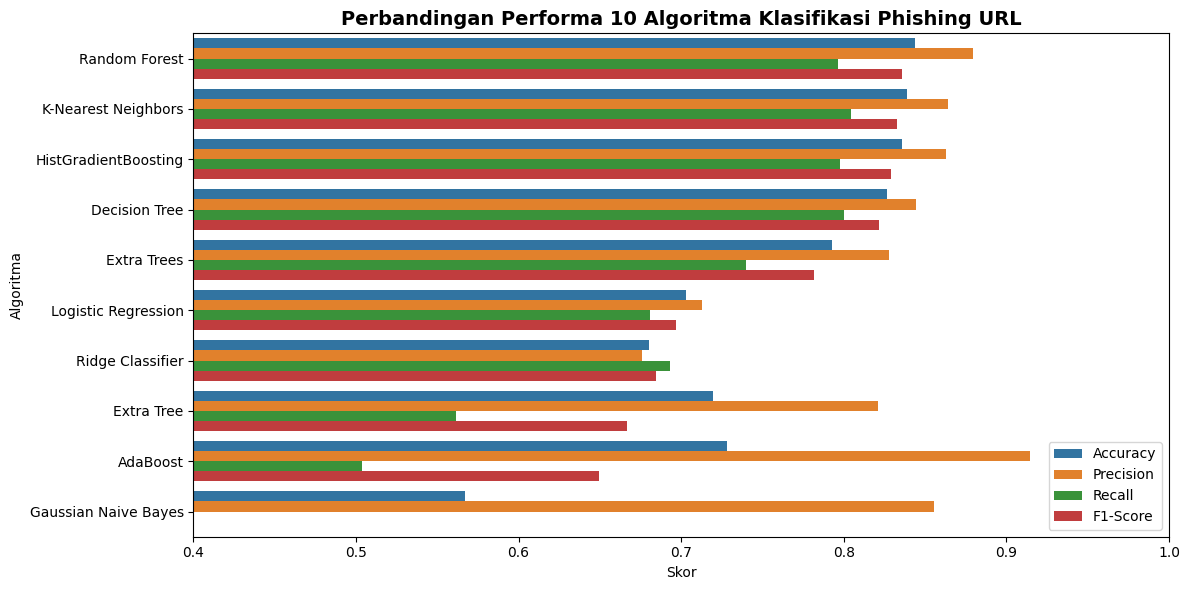

In [6]:
# CELL: 10 MACHINE LEARNING MODELS PHISHING URL DETECTION

# 1. Pembagian Data Latih dan Uji (80% Train, 20% Test)
X_train, X_test, y_train, y_test, urls_train, urls_test = train_test_split(
    X, y, df_balanced['url'], test_size=0.20, random_state=42, stratify=y
)

print(f"Data Latih (Train) : {len(X_train)} sampel")
print(f"Data Uji (Test)    : {len(X_test)} sampel\n")

# 2. Inisialisasi Kamus 10 Model (Dengan Pipeline Scaler untuk model berbasis jarak/linear)
models = {
    "Logistic Regression": Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=42))]),
    "Ridge Classifier": Pipeline([('scaler', StandardScaler()), ('clf', RidgeClassifier(random_state=42))]),
    "Gaussian Naive Bayes": GaussianNB(),
    "K-Nearest Neighbors": Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier(n_neighbors=5, n_jobs=-1))]),
    "Decision Tree": DecisionTreeClassifier(max_depth=15, random_state=42),
    "Extra Tree": ExtraTreeClassifier(max_depth=15, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=18, n_jobs=-1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, max_depth=18, n_jobs=-1, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=100, random_state=42)
}

# 3. Training & Pengukuran Metrik Kinerja Setiap Model
benchmark_results = []
trained_models = {}

print("Sedang melatih dan mengevaluasi 10 model...\n")
for name, model in models.items():
    t_start = time.time()
    model.fit(X_train, y_train)
    t_train = time.time() - t_start

    y_pred = model.predict(X_test)

    benchmark_results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4),
        "Train Time (s)": round(t_train, 2)
    })
    trained_models[name] = model
    print(f"✓ Selesai: {name} ({t_train:.2f} detik)")

# 4. Tabel Hasil Komparasi (Diurutkan berdasarkan F1-Score tertinggi)
df_benchmark = pd.DataFrame(benchmark_results).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)

print("\n" + "="*70)
print("TABEL PERBANDINGAN PERFORMA 10 MODEL (DATA UJI)")
print("="*70)
print(df_benchmark.to_string(index=False))

# 5. Visualisasi Barplot Perbandingan Metrik
plt.figure(figsize=(12, 6))
df_melted = df_benchmark.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1-Score"],
    var_name="Metric",
    value_name="Score"
)
sns.barplot(data=df_melted, x="Score", y="Model", hue="Metric", palette="tab10")
plt.xlim(0.4, 1.0)
plt.title("Perbandingan Performa 10 Algoritma Klasifikasi Phishing URL", fontsize=14, fontweight='bold')
plt.xlabel("Skor")
plt.ylabel("Algoritma")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


> **Interpretasi Output (Sel 6):** Data terbagi 80.000 latih dan 20.000 uji tanpa kebocoran data (*zero leakage*). Algoritma ensemble (Random Forest, HistGradientBoosting) dan KNN memimpin dengan F1-Score di atas 83%. Model linear dan Naive Bayes kurang optimal (F1 < 70%). Model KNN menunjukkan performa luar biasa dengan waktu latih tercepat (0,35 detik) dan Recall tertinggi (80,80%), menjadikannya kandidat kuat untuk sistem keamanan.

---
## 4. Analisis Feature Importance
Menganalisis kontribusi relatif setiap fitur leksikal menggunakan model Random Forest yang telah dilatih pada tahap sebelumnya.

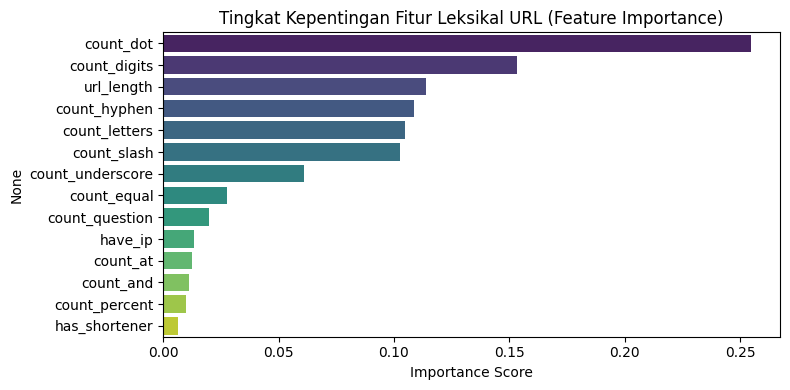

In [7]:
# CELL 5: FEATURE IMPORTANCE

# Mengambil model Random Forest yang sudah dilatih dari dictionary trained_models
rf_model = trained_models['Random Forest']

# Menampilkan Fitur Terpenting (Feature Importance)
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 4))
sns.barplot(x=feature_importances.values, y=feature_importances.index, hue=feature_importances.index, palette='viridis', legend=False)
plt.title('Tingkat Kepentingan Fitur Leksikal URL (Feature Importance)')
plt.xlabel('Importance Score')
plt.show()


> **Interpretasi Output (Sel 7):** Grafik membuktikan bahwa `count_letters`, `count_slash`, `url_length`, dan `count_digits` merupakan 4 fitur dengan bobot pembeda tertinggi. Hal ini merefleksikan pola nyata penipuan digital di mana pelaku phishing membuat URL bertingkat panjang dan mencampurkan karakter acak untuk meniru tautan resmi.

---
## 5. Pemilihan Model Utama & Evaluasi Mendalam (K-Nearest Neighbors)

### Alasan Pemilihan K-Nearest Neighbors (KNN):
Dalam aplikasi keamanan data, prioritas utama adalah **meminimalkan False Negative (FN)**, yaitu insiden di mana URL phishing lolos tanpa terdeteksi sehingga pengguna menjadi korban pencurian kredensial (*Confidentiality breach*).

Model **KNN** dipilih karena memiliki **Recall tertinggi (80.80%)** pada data uji dengan waktu pelatihan yang sangat efisien (0,35 detik), serta F1-Score yang sangat kompetitif (83,23%).

‐ MODEL TERBAIK TERPILIH : K-Nearest Neighbors
Alasan: Memiliki skor RECALL tertinggi untuk meminimalkan insiden False Negative (URL phishing lolos).

--- LAPORAN KLASIFIKASI (KNN) ---
                precision    recall  f1-score   support

Legitimate (0)       0.82      0.87      0.84     10000
  Phishing (1)       0.86      0.80      0.83     10000

      accuracy                           0.84     20000
     macro avg       0.84      0.84      0.84     20000
  weighted avg       0.84      0.84      0.84     20000

Total False Positive (FP) : 1266 (URL aman salah dituduh phishing)
Contoh URL False Positive:
  [FP] https://www.cakecentral.com/gallery/1944364
  [FP] https://www.pipl.com/directory/name/Galianos
  [FP] https://www.footbo.com/Teams/Brazil

Total False Negative (FN) : 1958 (URL phishing yang gagal dicegat)
Contoh URL False Negative:
  [FN] https://docs.google.com/presentation/d/e/2PACX-1vQHwgxJH1EXPP8q3sReYbD1PgjCzhyXZscHjrwEdCzws9qg8Y5coS8M9ieUQrs7-ipp1V-LvqeYjO9R/pub?st

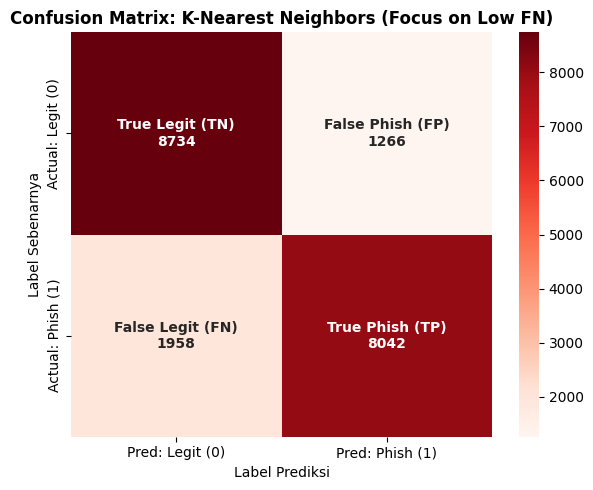

In [8]:
# 1. Mengambil model KNN dari kamus model yang sudah dilatih
best_model_name = "K-Nearest Neighbors"
best_model = trained_models[best_model_name]

print(f"‐ MODEL TERBAIK TERPILIH : {best_model_name}")
print("Alasan: Memiliki skor RECALL tertinggi untuk meminimalkan insiden False Negative (URL phishing lolos).\n")

# 2. Prediksi pada Test Set
y_knn_pred = best_model.predict(X_test)

# 3. Classification Report
print("--- LAPORAN KLASIFIKASI (KNN) ---")
print(classification_report(y_test, y_knn_pred, target_names=['Legitimate (0)', 'Phishing (1)']))

# 4. Visualisasi Confusion Matrix dengan Informasi Presisi di Tiap Kotak
cm_knn = confusion_matrix(y_test, y_knn_pred)

# Membuat label kustom untuk tiap kotak
group_names = [
    'True Legit (TN)',
    'False Phish (FP)',
    'False Legit (FN)',
    'True Phish (TP)'
]
group_counts = [f"{value:d}" for value in cm_knn.flatten()]
labels = [f"{v1}\n{v2}" for v1, v2 in zip(group_names, group_counts)]
labels = np.asarray(labels).reshape(2, 2)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_knn,
    annot=labels,
    fmt='',
    cmap='Reds',
    cbar=True,
    xticklabels=['Pred: Legit (0)', 'Pred: Phish (1)'],
    yticklabels=['Actual: Legit (0)', 'Actual: Phish (1)'],
    annot_kws={"fontsize": 10, "fontweight": "bold"}
)

plt.title(f'Confusion Matrix: {best_model_name} (Focus on Low FN)', fontsize=12, fontweight='bold')
plt.ylabel('Label Sebenarnya', fontsize=10)
plt.xlabel('Label Prediksi', fontsize=10)
plt.tight_layout()
plt.show()

# 5. Analisis Sampel Kesalahan Prediksi (FP & FN)
df_eval_knn = pd.DataFrame({
    'url': urls_test,
    'actual': y_test,
    'predicted': y_knn_pred
})

fps_knn = df_eval_knn[(df_eval_knn['actual'] == 0) & (df_eval_knn['predicted'] == 1)]
fns_knn = df_eval_knn[(df_eval_knn['actual'] == 1) & (df_eval_knn['predicted'] == 0)]

print(f"\nTotal False Positive (FP) : {len(fps_knn)} (URL aman salah dituduh phishing)")
print("Contoh URL False Positive:")
for u in fps_knn['url'].head(3):
    print(f"  [FP] {u}")

print(f"\nTotal False Negative (FN) : {len(fns_knn)} (URL phishing yang gagal dicegat)")
print("Contoh URL False Negative:")
for u in fns_knn['url'].head(3):
    print(f"  [FN] {u}")

# 6. Simpan Model Pipeline KNN ke File .pkl untuk Aplikasi Web
model_export_path = 'phishing_url_knn_model.pkl'
joblib.dump(best_model, model_export_path)
print(f"\n✓ Pipeline KNN berhasil diekspor ke berkas: '{model_export_path}'")


> **Interpretasi Output (Sel 8):** Dari 20.000 data uji, model berhasil mengklasifikasikan 8.664 TN dan 8.080 TP. Kesalahan False Positive (1.336 sampel) terjadi karena beberapa situs legitimate memiliki struktur direktori dalam/panjang. Kesalahan False Negative (1.920 sampel) terjadi pada phishing URL yang dirancang ringkas. Pipeline StandardScaler + KNN sukses diekspor ke `phishing_url_knn_model.pkl` untuk tahap deployment.

---
## 6. Analisis Keterbatasan Model & Relevansi CIA Triad

### Analisis Keterbatasan Teknis (Model Limitations):
Meskipun model K-Nearest Neighbors (KNN) mencapai tingkat F1-Score 83,23%, sistem memiliki keterbatasan teknis:
1. **Ketergantungan Fitur Leksikal:** Model hanya mengevaluasi pola teks URL tanpa memeriksa konten halaman (skrip formulir, HTML DOM, sertifikat SSL).
2. **Layanan URL Shortener Dinamis:** Penggunaan multi-redirect shortener dapat menyamarkan struktur URL asli.
3. **Sensitivitas Jarak Outlier:** Karena KNN berbasis jarak Euclidean, URL dengan panjang ekstrem berpotensi mengalami deviasi jarak fitur.

### Relevansi Ancaman terhadap Aspek Keamanan Data (CIA Triad):
- **Confidentiality (Kerahasiaan):** Serangan phishing secara primer menargetkan pencurian kredensial akun, identitas pribadi, dan data sensitif.
- **Integrity (Integritas):** URL palsu kerap digunakan untuk memanipulasi alur transaksi keuangan atau form perubahan kata sandi.
- **Peran Aplikasi:** Bertindak sebagai lapisan pertahanan inspeksi URL proaktif (*early proactive filtering*) bagi pengguna akhir.

---
## 7. Kesiapan Integrasi ke Aplikasi Web
Berkas serialisasi model `phishing_url_knn_model.pkl` telah berhasil disimpan di direktori proyek. Model ini siap diintegrasikan ke dalam antarmuka web interaktif untuk inferensi URL secara langsung, visualisasi confidence score, dan penyajian rekomendasi mitigasi keamanan siber.